<a href="https://colab.research.google.com/github/k1-r1ll/pytorch/blob/main/torch1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import warnings

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import numpy as np
from matplotlib import cm
from tqdm.auto import tqdm
import copy
from IPython.display import clear_output

In [3]:
warnings.filterwarnings("ignore")
%matplotlib inline

import torch
import torchvision

In [4]:
from torch import nn
import torch.nn.functional as F
import torch.optim as optim

In [5]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from torchvision.datasets import ImageFolder
from sklearn.model_selection import train_test_split

In [7]:
!pip install wget

  Preparing metadata (setup.py) ... done
  Created wheel for wget: filename=wget-3.2-py3-none-any.whl size=9686 sha256=9073faffa77f349fc3f643176e75bbdbeab7efbf6c176b56211bc10f264e762c
  Stored in directory: /root/.cache/pip/wheels/8a/b8/04/0c88fb22489b0c049bee4e977c5689c7fe597d6c4b0e7d0b6a
Successfully built wget


In [8]:
import wget

In [9]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [10]:
device

device(type='cuda', index=0)

In [11]:
!wget --no-check-certificate \
    https://storage.googleapis.com/tensorflow-1-public/course2/cats_and_dogs_filtered.zip \
    -O /content/cats_and_dogs_filtered.zip

!unzip -q /content/cats_and_dogs_filtered.zip -d ./data/

--2026-10-17 21:11:20--  https://storage.googleapis.com/tensorflow-1-public/course2/cats_and_dogs_filtered.zip
Resolving storage.googleapis.com (storage.googleapis.com)... 104.154.124.27, 34.3.0.27, 104.154.125.27, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|104.154.124.27|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 68606236 (65M) [application/zip]
Saving to: ‘/content/cats_and_dogs_filtered.zip’

/content/cats_and_d 100%[===================>]  65.43M  15.5MB/s    in 5.5s    

2026-10-17 21:11:27 (11.8 MB/s) - ‘/content/cats_and_dogs_filtered.zip’ saved [68606236/68606236]



In [12]:
from IPython.display import clear_output

def plot_losses(train_losses, test_losses, train_accuracies, test_accuracies):
    clear_output()
    fig, axs = plt.subplots(1, 2, figsize=(13, 4))
    axs[0].plot(range(1, len(train_losses) + 1), train_losses, label='train')
    axs[0].plot(range(1, len(test_losses) + 1), test_losses, label='test')
    axs[0].set_ylabel('loss')

    axs[1].plot(range(1, len(train_accuracies) + 1), train_accuracies, label='train')
    axs[1].plot(range(1, len(test_accuracies) + 1), test_accuracies, label='test')
    axs[1].set_ylabel('accuracy')

    for ax in axs:
        ax.set_xlabel('epoch')
        ax.legend()

    plt.show()

In [13]:
def training_epoch(model, optimizer, criterion, train_loader, tqdm_desc, wandb_project=None):
    """Одна эпоха обучения"""
    train_loss, train_accuracy = 0.0, 0.0
    model.train()
    for images, labels in tqdm(train_loader, desc=tqdm_desc):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.shape[0]
        train_accuracy += (logits.argmax(dim=1) == labels).sum().item()

        if wandb_project:
            metrics = {
                "batch-train/loss": loss.item()
            }
            wandb.log(metrics)

    train_loss /= len(train_loader.dataset)
    train_accuracy /= len(train_loader.dataset)
    return train_loss, train_accuracy

In [14]:
@torch.no_grad()
def validation_epoch(model, criterion, val_loader, tqdm_desc):
    """Прогнозы на валидации"""

    val_loss, val_accuracy = 0.0, 0.0
    model.eval()
    for images, labels in tqdm(val_loader, desc=tqdm_desc):
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        loss = criterion(logits, labels)

        val_loss += loss.item() * images.shape[0]
        val_accuracy += (logits.argmax(dim=1) == labels).sum().item()

    val_loss /= len(val_loader.dataset)
    val_accuracy /= len(val_loader.dataset)
    return val_loss, val_accuracy

In [15]:
def train(model, optimizer, criterion, train_loader, val_loader, num_epochs, scheduler=None, wandb_project=None):
    """Обучение модели"""
    train_losses, train_accuracies = [], []
    val_losses, val_accuracies = [], []

    if wandb_project:
        wandb.init(project=wandb_project)
        wandb.watch(model)

    for epoch in range(1, num_epochs + 1):
        train_loss, train_accuracy = training_epoch(
            model, optimizer, criterion, train_loader,
            tqdm_desc=f'Training {epoch}/{num_epochs}',
            wandb_project=wandb_project
        )
        val_loss, val_accuracy = validation_epoch(
            model, criterion, val_loader,
            tqdm_desc=f'Validating {epoch}/{num_epochs}'
        )

        train_losses.append(train_loss)
        train_accuracies.append(train_accuracy)
        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)

        if scheduler is not None:
            scheduler.step()

        if wandb_project:
            metrics = {
                "train/loss": train_loss / len(train_loader.dataset),
                "train/accuracy": train_accuracy / len(train_loader.dataset),
                "val/loss": val_loss,
                "val/accuracy": val_accuracy
            }
            wandb.log(metrics)
        else:
          plot_losses(train_losses, val_losses, train_accuracies, val_accuracies)

    print(f"Epoch: {epoch}, loss: {np.mean(val_loss)}, accuracy: {np.mean(val_accuracy)}")

In [16]:
normalize = T.Normalize(mean=[0.4914, 0.4822, 0.4465],
            std=[0.247, 0.243, 0.261])

train_transform = T.Compose([
    T.RandomResizedCrop(224),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    normalize
])

test_transform = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
    normalize
])

train_full = ImageFolder(
    "data/cats_and_dogs_filtered/train",
    transform = train_transform
)

val_full = ImageFolder(
    "data/cats_and_dogs_filtered/train",
    transform = train_transform
    #transform = test_transform
)

generator = torch.Generator().manual_seed(42)

train_idx, val_idx = torch.utils.data.random_split(
    range(len(train_full)),
    [int(0.8 * len(train_full)), len(train_full) - int(0.8 * len(train_full))],
    generator=generator
)

train_dataset = torch.utils.data.Subset(
    train_full, train_idx.indices
)
val_dataset = torch.utils.data.Subset(
    val_full, val_idx.indices
)

test_dataset = ImageFolder(
    "data/cats_and_dogs_filtered/validation",
    transform = test_transform
)

In [20]:
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size     = 32,
    shuffle        = True,
    pin_memory=device.type == "cuda",
    num_workers    = 2
)

val_loader = torch.utils.data.DataLoader(
    val_dataset,
    batch_size     = 4096,
    shuffle        = False,
    pin_memory=device.type == "cuda",
    num_workers    = 2
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size     = 4096,
    shuffle        = False,
    pin_memory=device.type == "cuda",
    num_workers    = 2
)

In [21]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=2):

        super().__init__()
        self.features = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1, 1)),
        )

        self.classifier = nn.Linear(128, num_classes,)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)

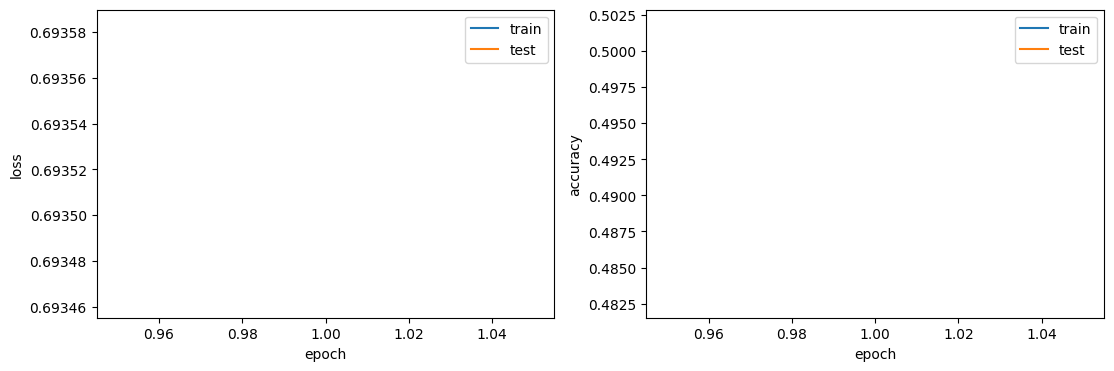

Epoch: 1, loss: 0.6934612989425659, accuracy: 0.4825


In [23]:
NUM_EPOCH = 1
model_cnn = SimpleCNN(num_classes=2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_cnn.parameters(), lr=0.01, momentum=0)

history = train(

    model_cnn, optimizer, criterion,
    train_loader, val_loader,
    NUM_EPOCH

)